# Mô hình hóa động lực học vận chuyển O₂ trong tuần hoàn máu của chim cánh cụt hoàng đế khi lặn



| Mục | Nội dung | Phương trình |
|---|---|---|
| 1 | Nạp dữ liệu, kiểm tra Hill, dựng bảng cú lặn + cửa sổ sạch | (1)–(3) |
| 2 | Mô hình $S_a(t)$ và hiệu chuẩn $k$, $\tau_a$, hệ số $\Delta S_a$ từ dữ liệu động mạch | (4)–(5) |
| 3 | ODE bể tĩnh mạch, nghiệm rời rạc chính xác, kiểm tra với `solve_ivp` | (6)–(9) |
| 4 | Ước lượng tham số: phương án 4 tham số (trong lúc lặn) và 7 tham số (toàn chu kỳ) | (10) |
| 5 | Kết quả, so sánh Type A vs Type B, quy đổi sang hiệu số a-v (mL O₂/dL) | |
| 6 | Kiểm định ngoài mẫu (leave-one-bird-out), độ nhạy theo $\tau$, nghịch đảo trực tiếp $g(t)$ | |

**Quan sát then chốt:** với $\tau$, $S_a(t)$ và các mốc pha cố định, $S_v(t)$ là hàm *tuyến tính* của $\Theta=(S_{init}, g_{\cdot})$.
Do đó bài toán NLS (10) thực chất là bình phương tối thiểu tuyến tính có ràng buộc biên → nghiệm tối ưu toàn cục,
không cần đoán giá trị đầu, không kẹt cực tiểu địa phương. Notebook dùng `lsq_linear` và kiểm tra chéo với mô phỏng trực tiếp.

## 1. Cấu hình, nạp dữ liệu

In [2]:
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, lsq_linear
from scipy.signal import lfilter, savgol_filter

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# ---- đường dẫn: notebooks/ và data/ cùng cấp
DATA_DIR = Path("../data")
RES_DIR  = Path("../results"); RES_DIR.mkdir(exist_ok=True)

# ---- hằng số sinh lý & mô hình (main3.pdf)
P50, N_HILL   = 28.2, 2.93        # Hill, pH 7.5
TAU           = 0.35              # phút; hằng số trộn bể tĩnh mạch (đồ án: 0.25-0.50) -> xem mục 6.2
DT            = 0.05              # phút; bước rời rạc hóa
PRE_S, POST_S = 300, 420          # cửa sổ [t_start-300 s, t_end+420 s]
SA_REST, SA_START = 0.97, 0.987   # S_a trước lặn / đầu lặn
COEF_A, COEF_B, DSA_MAX = -0.141, 0.183, 0.6   # ΔSa = clip(a + b ln Td, 0, 0.6)  (phương trình 5)
G_MAX         = 1.0               # cận trên của g (không thứ nguyên), cận dưới = 0 (g=(1-f)m/Q >= 0)
HB_G_DL, O2_PER_G_HB = 18.0, 1.34 # để quy đổi g -> hiệu số a-v (mL O2/dL), như Fig. 7 của bài báo
AV_FACTOR = HB_G_DL * O2_PER_G_HB # = 24.12 mL O2/dL ứng với 100% bão hòa
CLEAN_MODE = "strict"             # "strict": loại cả cú lặn 'unlisted'; "listed_only": chỉ loại các cú lặn có trong danh sách

In [3]:
merged = pd.read_csv(DATA_DIR / "penguin_merged.csv")
dives  = pd.read_csv(DATA_DIR / "penguin_dives.csv")
print("merged:", merged.shape, "| dives:", dives.shape)
print(merged.groupby("site").bird.unique().to_string())
print()
print("Số cú lặn theo nhóm (bảng dives):\n", dives.group.value_counts().to_string())
print("\nSố cú lặn có dữ liệu trong merged:\n", merged.dropna(subset=['dive_id']).groupby('group').dive_id.nunique().to_string())

merged: (29511, 15) | dives: (160, 14)
site
arterial                      [EP01, EP02, EP08, EP10, EP36A]
venous      [EP04, EP05, EP07, EP17, EP19, EP20, EP36, EP3...

Số cú lặn theo nhóm (bảng dives):
 group
Type B venous    65
Arterial         64
Type A venous    31

Số cú lặn có dữ liệu trong merged:
 group
Arterial         63
Type A venous    29
Type B venous    65


### 1.1 Kiểm tra phương trình Hill (3)
Cột `Hb` trong file merged được tạo từ `PO2` qua đường cong Hill. Kiểm tra lại với $P_{50}=28{,}2$ và $n=2{,}93$.

In [4]:
def hill(P, p50=P50, n=N_HILL):
    P = np.asarray(P, float)
    return P**n / (P**n + p50**n)

err = (hill(merged.PO2) - merged.Hb).abs()
print(f"|Hill(PO2) - Hb|: max = {err.max():.2e}, mean = {err.mean():.2e}  -> cột Hb đúng là Hill(P50=28.2, n=2.93)")
assert err.max() < 1e-3

|Hill(PO2) - Hb|: max = 5.18e-04, mean = 2.58e-04  -> cột Hb đúng là Hill(P50=28.2, n=2.93)


### 1.2 Bảng cú lặn: mốc thời gian tuyệt đối, hợp lệ, cửa sổ sạch
Trục thời gian `t` của file merged là *liên tục theo từng cá thể* (xem phương trình 1: $t_{start}=t-t_{in\_dive\_s}$).
Cột `start`/`end` của bảng dives lại là giây-trong-ngày (`tod`), nên cần quy đổi bằng độ lệch $t-tod$ theo (bird, date).
Cú lặn `unlisted_dive` trong merged là các đoạn có độ sâu nhưng không nằm trong danh sách (thường < 2 phút) — chúng vẫn "giao thoa" cửa sổ nên bị loại khi `CLEAN_MODE="strict"`.

In [5]:
merged["dkey"] = merged.date.fillna("")
offset_tab = (merged.assign(o=merged.t - merged.tod).groupby(["bird", "dkey"]).o.median())

D = dives.copy()
D["dkey"] = D.date.fillna("")
D["off"] = [offset_tab.get((b, k), np.nan) for b, k in zip(D.bird, D.dkey)]
# cú lặn thiếu date (không có dữ liệu trong merged): lấy độ lệch từ hàng gần nhất trong giây-trong-ngày
for i in D.index[D.off.isna()]:
    g = merged[merged.bird == D.at[i, "bird"]]
    j = (g.tod - D.at[i, "start"]).abs().idxmin()
    D.at[i, "off"] = g.at[j, "t"] - g.at[j, "tod"]
D["ts"] = D.start + D.off
D["te"] = D.end + D.off
D["Td"] = D.dur_min
D["in_merged"] = D.dive_id.isin(merged.dive_id.dropna().unique())
D["type"] = D.group.map({"Arterial": "Arterial", "Type A venous": "A", "Type B venous": "B"})

def window_is_clean(row, mode=CLEAN_MODE):
    # Cửa sổ [ts-300, te+420] sạch nếu: (i) dữ liệu phủ kín cửa sổ, (ii) không giao với cú lặn khác của cùng cá thể,
    # (iii) (strict) không chứa hàng 'unlisted_dive'.
    lo, hi = row.ts - PRE_S, row.te + POST_S
    g = merged[(merged.bird == row.bird) & (merged.t >= lo) & (merged.t <= hi)]
    if len(g) == 0:
        return False
    covered = (g.t.min() <= lo + 15) and (g.t.max() >= hi - 15)
    others = D[(D.bird == row.bird) & (D.dive_id != row.dive_id) & (D.ts < hi) & (D.te > lo)]
    ok = covered and len(others) == 0
    if mode == "strict":
        ok = ok and (not g.unlisted_dive.any())
    return bool(ok)

D["valid"] = D.is_valid_dive & D.in_merged & ~D.dive_id.isin(merged.loc[merged.excluded_dive, "dive_id"].unique())
D["clean"] = [window_is_clean(r) if r.valid else False for r in D.itertuples()]
D = D.set_index("dive_id", drop=False)

print(D[D.valid].groupby("type").agg(n=("dive_id", "size"), n_clean=("clean", "sum"),
                                     Td_mean=("Td", "mean"), Td_max=("Td", "max"), zmax_mean=("max_depth_clean", "mean")).round(2))
n_long = int(((D.type == "B") & D.valid & (D.Td > 11.7)).sum())
print(f"\nSố cú lặn Type B hợp lệ có Td > 11.7 phút (ngoại suy Sa): {n_long}/{int(((D.type=='B') & D.valid).sum())}")

           n  n_clean  Td_mean  Td_max  zmax_mean
type                                             
A         28        2     3.93    9.08      26.97
Arterial  63       15     5.50   11.68      29.52
B         65       25     9.24   23.13      54.44

Số cú lặn Type B hợp lệ có Td > 11.7 phút (ngoại suy Sa): 16/65


> **Lưu ý quan trọng về phương án toàn chu kỳ (7 tham số):** các cú lặn Type A rất ngắn và thường đi thành chuỗi,
> nên chỉ rất ít cửa sổ 5 phút trước + 7 phút sau không bị chuyến lặn khác chen vào (xem bảng trên, cột `n_clean`).
> Phương án 4 tham số (chỉ trong lúc lặn) vì vậy là phương án chính cho so sánh A vs B; phương án 7 tham số chỉ dùng được trọn vẹn cho Type B.

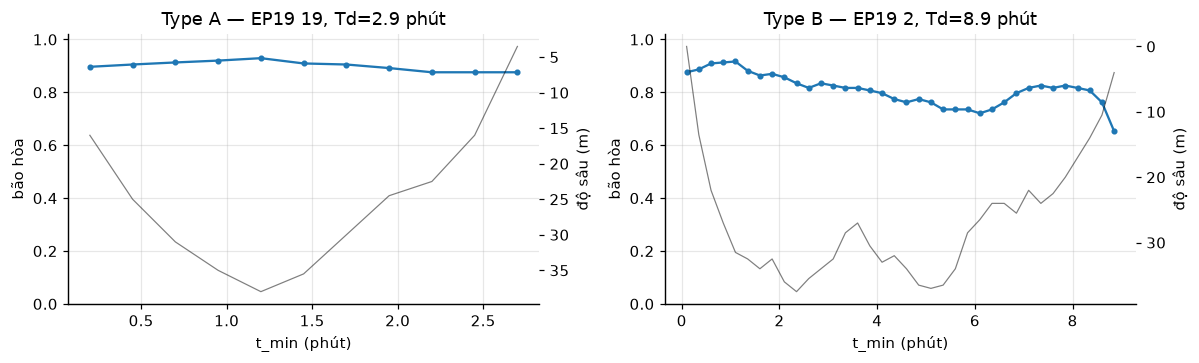

In [6]:
def get_series(row, mode):
    # Chuỗi quan sát S_v(t_min). mode='dive': chỉ khi lặn; mode='window': cả cửa sổ [ts-300, te+420].
    if mode == "dive":
        g = merged[merged.dive_id == row.dive_id]
        tmin = g.t_in_dive_s.to_numpy() / 60
    else:
        g = merged[(merged.bird == row.bird) & (merged.t >= row.ts - PRE_S) & (merged.t <= row.te + POST_S)]
        tmin = (g.t.to_numpy() - row.ts) / 60
    return pd.DataFrame({"tmin": tmin, "S": g.Hb.to_numpy(), "depth": g.depth_m.to_numpy()})

# ví dụ 1 cú lặn Type A và 1 cú Type B
ex = {"A": D[(D.type == "A") & D.valid].sort_values("Td").dive_id.iloc[10],
      "B": D[(D.type == "B") & D.valid].sort_values("Td").dive_id.iloc[30]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a_, (k_, did) in zip(ax, ex.items()):
    s = get_series(D.loc[did], "dive")
    a_.plot(s.tmin, s.S, "o-", ms=3, label="$S_v$ đo (Hb)")
    a2 = a_.twinx(); a2.plot(s.tmin, s.depth, "k-", lw=.8, alpha=.5); a2.invert_yaxis(); a2.set_ylabel("độ sâu (m)"); a2.grid(False)
    a_.set(title=f"Type {k_} — {did}, Td={D.loc[did].Td:.1f} phút", xlabel="t_min (phút)", ylabel="bão hòa", ylim=(0, 1.02))
plt.tight_layout(); plt.show()

## 2. Thành phần 1 — đường cong động mạch mẫu $S_a(t_{min})$

$$
S_a=\begin{cases}0{,}97 & t<0\\ 0{,}987-\Delta S_a\,x^{k} & 0\le t\le T_d\\ 0{,}97-(0{,}97-S_{end})e^{-(t-T_d)/\tau_a} & t>T_d\end{cases},\qquad
\Delta S_a=\mathrm{clip}(a+b\ln T_d,0,0{,}6)
$$

File main3 ghi $k$ và $\tau_a$ là "hồi quy mẫu $S_a$" nhưng chưa nêu giá trị, nên ở đây **ước lượng từ dữ liệu động mạch** (5 cá thể, 63 cú lặn).
Hệ số $a,b$ của $\Delta S_a$ cũng được hồi quy lại từ dữ liệu để đối chiếu với $(-0{,}141;\ 0{,}183)$ trong main3.

In [7]:
def delta_sa(Td, a=COEF_A, b=COEF_B):
    return np.clip(a + b * np.log(Td), 0.0, DSA_MAX)

def sa_curve(tmin, Td, k, tau_a, a=COEF_A, b=COEF_B):
    tmin = np.asarray(tmin, float)
    dS   = delta_sa(Td, a, b)
    Send = SA_START - dS
    x    = np.clip(tmin / Td, 0, 1)
    during = SA_START - dS * x**k
    post   = SA_REST - (SA_REST - Send) * np.exp(-np.maximum(tmin - Td, 0) / tau_a)
    return np.where(tmin < 0, SA_REST, np.where(tmin <= Td, during, post))

art = D[(D.type == "Arterial") & D.valid]
art_in = pd.concat([get_series(r, "dive").assign(dive_id=r.dive_id, Td=r.Td) for r in art.itertuples()])
art_in["x"] = art_in.tmin / art_in.Td

# (a) hồi quy ΔSa theo ln Td, dùng S cuối cú lặn (trung bình 3 mẫu cuối để giảm nhiễu)
end_tab = art_in.sort_values("tmin").groupby("dive_id").agg(Td=("Td", "first"), S_end=("S", lambda s: s.iloc[-3:].mean()))
end_tab["dS"] = SA_START - end_tab.S_end
reg = stats.linregress(np.log(end_tab.Td), end_tab.dS)
print(f"Hồi quy lại ΔSa = {reg.intercept:+.3f} + {reg.slope:.3f}·ln Td  (R²={reg.rvalue**2:.2f}, n={len(end_tab)})")
print(f"Hệ số trong main3 : ΔSa = {COEF_A:+.3f} + {COEF_B:.3f}·ln Td  -> dùng giá trị main3 (đổi COEF_A/COEF_B nếu muốn dùng hồi quy lại)")

# (b) k: bình phương tối thiểu trên toàn bộ mẫu động mạch khi lặn
res_k = least_squares(lambda p: SA_START - delta_sa(art_in.Td) * art_in.x**p[0] - art_in.S, x0=[4.0], bounds=(0.5, 30))
K_SA = float(res_k.x[0])
rm_k = np.sqrt(np.mean(res_k.fun**2))
print(f"k = {K_SA:.2f}  (RMSE khi lặn = {rm_k:.3f})")

Hồi quy lại ΔSa = -0.124 + 0.175·ln Td  (R²=0.37, n=63)
Hệ số trong main3 : ΔSa = -0.141 + 0.183·ln Td  -> dùng giá trị main3 (đổi COEF_A/COEF_B nếu muốn dùng hồi quy lại)
k = 4.94  (RMSE khi lặn = 0.042)


In [8]:
# (c) tau_a: mẫu động mạch sau lặn trong (Td, Td+7 phút], loại cửa sổ có cú lặn khác chen vào
post_rows = []
for r in art.itertuples():
    lo, hi = r.te, r.te + POST_S
    if len(D[(D.bird == r.bird) & (D.dive_id != r.dive_id) & (D.ts < hi) & (D.te > lo)]) > 0:
        continue
    g = merged[(merged.bird == r.bird) & (merged.t > lo) & (merged.t <= hi)]
    if len(g) < 10 or g.unlisted_dive.any():
        continue
    post_rows.append(pd.DataFrame({"dive_id": r.dive_id, "Td": r.Td, "tmin": (g.t.to_numpy() - r.ts) / 60, "S": g.Hb.to_numpy()}))
post = pd.concat(post_rows)
print("Số cú lặn động mạch có đoạn phục hồi sạch:", post.dive_id.nunique())

res_t = least_squares(lambda p: sa_curve(post.tmin, post.Td, K_SA, p[0]) - post.S, x0=[1.0], bounds=(0.05, 10))
TAU_A = float(res_t.x[0])
print(f"tau_a = {TAU_A:.2f} phút (RMSE sau lặn = {np.sqrt(np.mean(res_t.fun**2)):.3f})")

SA_PARAMS = dict(k=K_SA, tau_a=TAU_A)
json.dump({"k": K_SA, "tau_a": TAU_A, "coef_a": COEF_A, "coef_b": COEF_B,
           "refit_intercept": reg.intercept, "refit_slope": reg.slope}, open(RES_DIR / "sa_calibration.json", "w"), indent=1)

Số cú lặn động mạch có đoạn phục hồi sạch: 27
tau_a = 1.34 phút (RMSE sau lặn = 0.052)


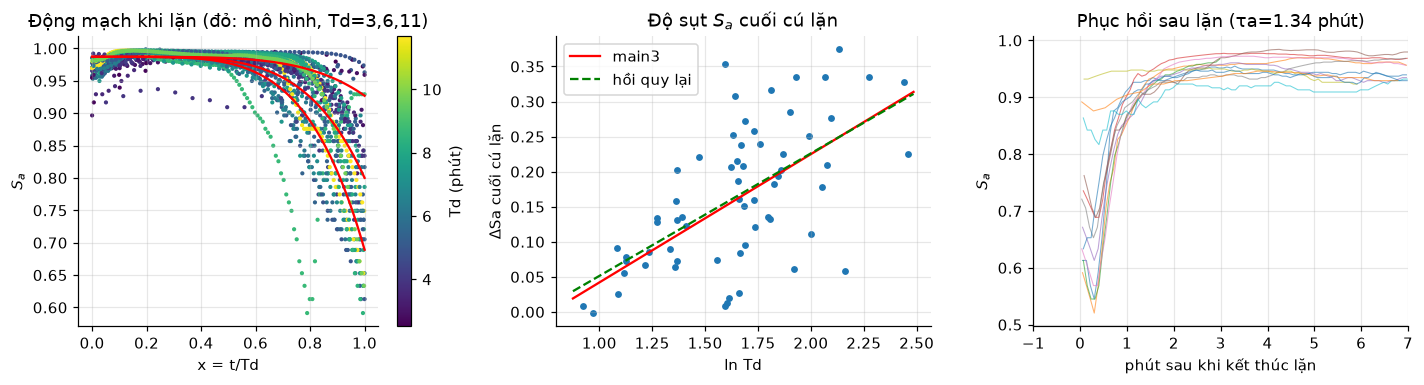

RMSE S_a mẫu vs đo (động mạch, khi lặn): 0.042


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (i) S_a theo x, màu theo Td
sc = ax[0].scatter(art_in.x, art_in.S, c=art_in.Td, s=3, cmap="viridis")
xs = np.linspace(0, 1, 100)
for Td_ in (3, 6, 11):
    ax[0].plot(xs, sa_curve(xs * Td_, Td_, K_SA, TAU_A), "r-", lw=1.5)
ax[0].set(xlabel="x = t/Td", ylabel="$S_a$", title="Động mạch khi lặn (đỏ: mô hình, Td=3,6,11)"); plt.colorbar(sc, ax=ax[0], label="Td (phút)")
# (ii) hồi quy ΔSa
ax[1].scatter(np.log(end_tab.Td), end_tab.dS, s=12)
lx = np.linspace(np.log(2.4), np.log(12), 50)
ax[1].plot(lx, delta_sa(np.exp(lx)), "r-", label="main3"); ax[1].plot(lx, reg.intercept + reg.slope * lx, "g--", label="hồi quy lại")
ax[1].set(xlabel="ln Td", ylabel="ΔSa cuối cú lặn", title="Độ sụt $S_a$ cuối cú lặn"); ax[1].legend()
# (iii) phục hồi sau lặn
for did, g in list(post.groupby("dive_id"))[:12]:
    ax[2].plot(g.tmin - g.Td.iloc[0], g.S, lw=.7, alpha=.6)
ax[2].set(xlabel="phút sau khi kết thúc lặn", ylabel="$S_a$", title=f"Phục hồi sau lặn (τa={TAU_A:.2f} phút)"); ax[2].set_xlim(-1, 7)
plt.tight_layout(); plt.savefig(RES_DIR / "fig_sa_calibration.png", dpi=150); plt.show()

# sai số của S_a mẫu trên chính dữ liệu động mạch (trong mẫu)
pred = sa_curve(art_in.tmin, art_in.Td, **SA_PARAMS)
print(f"RMSE S_a mẫu vs đo (động mạch, khi lặn): {np.sqrt(np.mean((pred-art_in.S)**2)):.3f}")

## 3. Thành phần 2 — ODE bể tĩnh mạch và nghiệm rời rạc chính xác

$$\tau\frac{dS_v}{dt}=S_a(t)-g(t)-S_v,\qquad S_{v,j+1}=S_{v,j}e^{-\Delta t/\tau}+(1-e^{-\Delta t/\tau})\,[S_a(t_j)-g(t_j)]$$

Hàm $g(t)$ hằng từng đoạn theo 7 giai đoạn (phương trình 8); mốc pha chuẩn hóa theo $x=t_{min}/T_d$.

In [10]:
PARAMS_4 = ["S_init", "g1", "g2", "g3"]
PARAMS_7 = ["S_init", "g_rest", "g1", "g2", "g3", "gp1", "gp2"]

def phase_of(tmin, Td):
    # nhãn giai đoạn của g(t) (phương trình 8)
    t = np.round(np.asarray(tmin, float), 9)
    x = t / Td
    ph = np.full(t.shape, "rest", dtype=object)
    ph[(t >= 0) & (x < 1/3)]               = "g1"
    ph[(x >= 1/3) & (x < 2/3)]             = "g2"
    ph[(x >= 2/3) & (t <= Td)]             = "g3"
    ph[(t > Td) & (t <= Td + 1)]           = "gp1"
    ph[(t > Td + 1) & (t <= Td + 3)]       = "gp2"
    return ph

def g_of_t(tmin, Td, theta):
    ph = phase_of(tmin, Td)
    return np.array([theta.get(p, 0.0) if p != "rest" else theta.get("g_rest", 0.0) for p in ph])

def simulate_direct(tgrid, Td, theta, tau=TAU, sa_params=SA_PARAMS):
    # mô phỏng trực tiếp bằng vòng lặp công thức (9) — dùng để kiểm chứng và vẽ
    a = np.exp(-np.diff(tgrid)[0] / tau)
    u = sa_curve(tgrid, Td, **sa_params) - g_of_t(tgrid, Td, theta)
    S = np.empty_like(tgrid); S[0] = theta["S_init"]
    for j in range(len(tgrid) - 1):
        S[j + 1] = S[j] * a + (1 - a) * u[j]
    return S

def make_grid(Td, mode):
    t0 = -PRE_S / 60 if mode == "window" else 0.0
    t1 = Td + POST_S / 60 if mode == "window" else Td
    n = int(np.ceil(round((t1 - t0) / DT, 9)))
    return t0 + DT * np.arange(n + 1)

### 3.1 Kiểm chứng bộ giải
Hai kiểm tra: (i) công thức (9) khớp nghiệm số của `solve_ivp` với $g$ hằng từng đoạn; (ii) mô phỏng trực tiếp khớp biểu diễn tuyến tính dùng khi ước lượng.

In [11]:
def sv_ivp(Td, theta, tau=TAU, mode="window"):
    tgrid = make_grid(Td, mode)
    # cắt tại các mốc pha để g hằng trong từng đoạn
    knots = [0.0, Td/3, 2*Td/3, Td, Td+1, Td+3]
    knots = [k for k in knots if tgrid[0] < k < tgrid[-1]]
    edges = [tgrid[0]] + knots + [tgrid[-1]]
    S0, out_t, out_S = theta["S_init"], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mid = 0.5 * (lo + hi)
        gm = g_of_t(np.array([mid]), Td, theta)[0]
        f = lambda t, s, gm=gm: (np.interp(t, tgrid, sa_curve(tgrid, Td, **SA_PARAMS)) - gm - s) / tau
        sol = solve_ivp(f, (lo, hi), [S0], rtol=1e-9, atol=1e-11, dense_output=True, max_step=DT)
        tt = tgrid[(tgrid >= lo - 1e-12) & (tgrid <= hi + 1e-12)]
        out_t.append(tt); out_S.append(sol.sol(tt)[0]); S0 = sol.y[0, -1]
    return np.concatenate(out_t), np.concatenate(out_S)

theta_test = dict(S_init=0.85, g_rest=0.12, g1=0.05, g2=0.30, g3=0.20, gp1=0.45, gp2=0.25)
Td_test = 8.0
tg = make_grid(Td_test, "window")
S_dir = simulate_direct(tg, Td_test, theta_test)
t_iv, S_iv = sv_ivp(Td_test, theta_test)
S_iv_on_grid = np.interp(tg, t_iv, S_iv)
# công thức (9) lấy g ở đầu bước nên trễ 1 bước tại ranh giới pha (sai số O(Δt)); xa ranh giới hai nghiệm trùng nhau
err = np.abs(S_dir - S_iv_on_grid)
knots_ = np.array([0.0, Td_test/3, 2*Td_test/3, Td_test, Td_test+1, Td_test+3])
dist_ = tg[:, None] - knots_[None, :]
near = ((dist_ >= -3 * DT) & (dist_ <= 4 * TAU)).any(axis=1)   # sai lệch chuyển pha tắt dần như e^{-t/τ}: loại 4τ sau mỗi mốc
bound = max(abs(np.diff(list(theta_test.values())[1:]))) * DT / TAU     # độ trễ 1 bước tại ranh giới pha
print(f"max sai lệch (9) vs solve_ivp: xa mốc pha (>4τ) = {err[~near].max():.1e} ; gần mốc pha = {err[near].max():.4f} (cận lý thuyết ~Δg·Δt/τ = {bound:.4f})")
assert err[~near].max() < 5e-3 and err.max() < 1.2 * bound

max sai lệch (9) vs solve_ivp: xa mốc pha (>4τ) = 2.9e-03 ; gần mốc pha = 0.0355 (cận lý thuyết ~Δg·Δt/τ = 0.0357)


## 4. Ước lượng tham số (phương trình 10)

Vì $S_{v,j}=a^{j}S_{init}+\mathcal F[S_a]_j-\sum_p g_p\,\mathcal F[\mathbb 1_p]_j$ với $a=e^{-\Delta t/\tau}$ và $\mathcal F$ là bộ lọc IIR bậc 1,
ta dựng một **ma trận thiết kế** $X$ (mỗi cột là đáp ứng đơn vị của một tham số), nội suy tại thời điểm đo, rồi giải
$\min_\Theta\|S_{obs}-S_a^{filt}-X\Theta\|^2$ với $S_{init}\in[0,1]$, $g_p\in[0,1]$ bằng `lsq_linear` (BVLS).

In [12]:
def build_linear_system(Td, tmin_obs, names, mode, tau=TAU, sa_params=SA_PARAMS):
    tg = make_grid(Td, mode)
    a = np.exp(-DT / tau)
    filt = lambda z: lfilter([0.0, 1 - a], [1.0, -a], z)       # y[j] = a*y[j-1] + (1-a)*z[j-1]
    ph = phase_of(tg, Td)
    base = filt(sa_curve(tg, Td, **sa_params))                  # phần cưỡng bức bởi S_a
    cols = {"S_init": a ** np.arange(len(tg))}
    for nme in names[1:]:
        key = "rest" if nme == "g_rest" else nme
        cols[nme] = -filt((ph == key).astype(float))
    X_grid = np.column_stack([cols[n] for n in names])
    # nội suy về thời điểm đo
    X = np.column_stack([np.interp(tmin_obs, tg, X_grid[:, i]) for i in range(len(names))])
    b = np.interp(tmin_obs, tg, base)
    return X, b, tg, X_grid, base

def fit_dive(row, mode="dive", tau=TAU, sa_params=SA_PARAMS):
    names = PARAMS_4 if mode == "dive" else PARAMS_7
    s = get_series(row, mode)
    if mode == "dive":
        s = s[(s.tmin >= 0) & (s.tmin <= row.Td)]
    X, b, tg, Xg, base = build_linear_system(row.Td, s.tmin.to_numpy(), names, mode, tau, sa_params)
    y = s.S.to_numpy()
    sol = lsq_linear(X, y - b, bounds=(np.zeros(len(names)), np.r_[1.0, np.full(len(names) - 1, G_MAX)]), method="bvls")
    th = dict(zip(names, sol.x))
    pred = X @ sol.x + b
    resid = y - pred
    ss_tot = np.sum((y - y.mean())**2)
    ph = phase_of(s.tmin.to_numpy(), row.Td)
    out = dict(dive_id=row.dive_id, bird=row.bird, type=row.type, Td=row.Td, zmax=row.max_depth_clean, n_obs=len(y),
               rmse=np.sqrt(np.mean(resid**2)), mae=np.mean(np.abs(resid)), r2=1 - np.sum(resid**2) / ss_tot,
               **th)
    # số điểm đo trong mỗi pha -> đánh giá khả nhận dạng
    for nme in names[1:]:
        out["n_" + nme] = int(np.sum(ph == ("rest" if nme == "g_rest" else nme)))
    curve = dict(tg=tg, Sv=Xg @ sol.x + base, Sa=sa_curve(tg, row.Td, **sa_params))
    return out, s.assign(pred=pred), curve

# kiểm tra chéo: biểu diễn tuyến tính == mô phỏng trực tiếp
r0 = D.loc[ex["B"]]
o, _, cv = fit_dive(r0, "dive")
S_chk = simulate_direct(cv["tg"], r0.Td, {k: o[k] for k in PARAMS_4})
print(f"max |tuyến tính − mô phỏng trực tiếp| = {np.abs(S_chk - cv['Sv']).max():.2e}")
assert np.abs(S_chk - cv["Sv"]).max() < 1e-9

max |tuyến tính − mô phỏng trực tiếp| = 2.22e-16


### 4.1 Phương án 4 tham số — chỉ trong lúc lặn (tất cả cú lặn tĩnh mạch hợp lệ)

In [13]:
ven = D[D.valid & D.type.isin(["A", "B"])]
fits4, preds4, curves4 = [], {}, {}
for r in ven.itertuples():
    o, s, cv = fit_dive(D.loc[r.dive_id], "dive")
    fits4.append(o); preds4[r.dive_id] = s; curves4[r.dive_id] = cv
F4 = pd.DataFrame(fits4).set_index("dive_id")
F4.to_csv(RES_DIR / "fit_dive_only_4params.csv")
print(F4.groupby("type")[["n_obs", "rmse", "r2"]].agg(["mean", "median"]).round(3))
print(f"\nSố cú lặn: {len(F4)}  | số tham số chạm cận (g=0 hoặc g=1): "
      f"{int(((F4[['g1','g2','g3']]<1e-6)|(F4[['g1','g2','g3']]>G_MAX-1e-6)).sum().sum())} / {3*len(F4)}")

       n_obs          rmse            r2       
        mean median   mean median   mean median
type                                           
A     22.714   14.5  0.027  0.020 -1.416  0.822
B     40.754   39.0  0.054  0.051  0.748  0.798

Số cú lặn: 93  | số tham số chạm cận (g=0 hoặc g=1): 13 / 279


### 4.2 Phương án 7 tham số — toàn chu kỳ trên cửa sổ sạch

In [14]:
clean_ids = D[D.valid & D.clean & D.type.isin(["A", "B"])].dive_id
fits7, preds7, curves7 = [], {}, {}
for did in clean_ids:
    o, s, cv = fit_dive(D.loc[did], "window")
    fits7.append(o); preds7[did] = s; curves7[did] = cv
F7 = pd.DataFrame(fits7).set_index("dive_id")
F7.to_csv(RES_DIR / "fit_full_cycle_7params.csv")
print("Số cửa sổ sạch dùng được:", F7.groupby("type").size().to_dict())
print(F7.groupby("type")[["n_obs", "rmse", "r2"]].agg(["mean", "median"]).round(3))

Số cửa sổ sạch dùng được: {'A': 2, 'B': 25}
       n_obs          rmse            r2       
        mean median   mean median   mean median
type                                           
A     163.00  163.0  0.083  0.083  0.818  0.818
B      91.84   86.0  0.066  0.060  0.776  0.812


## 5. Kết quả

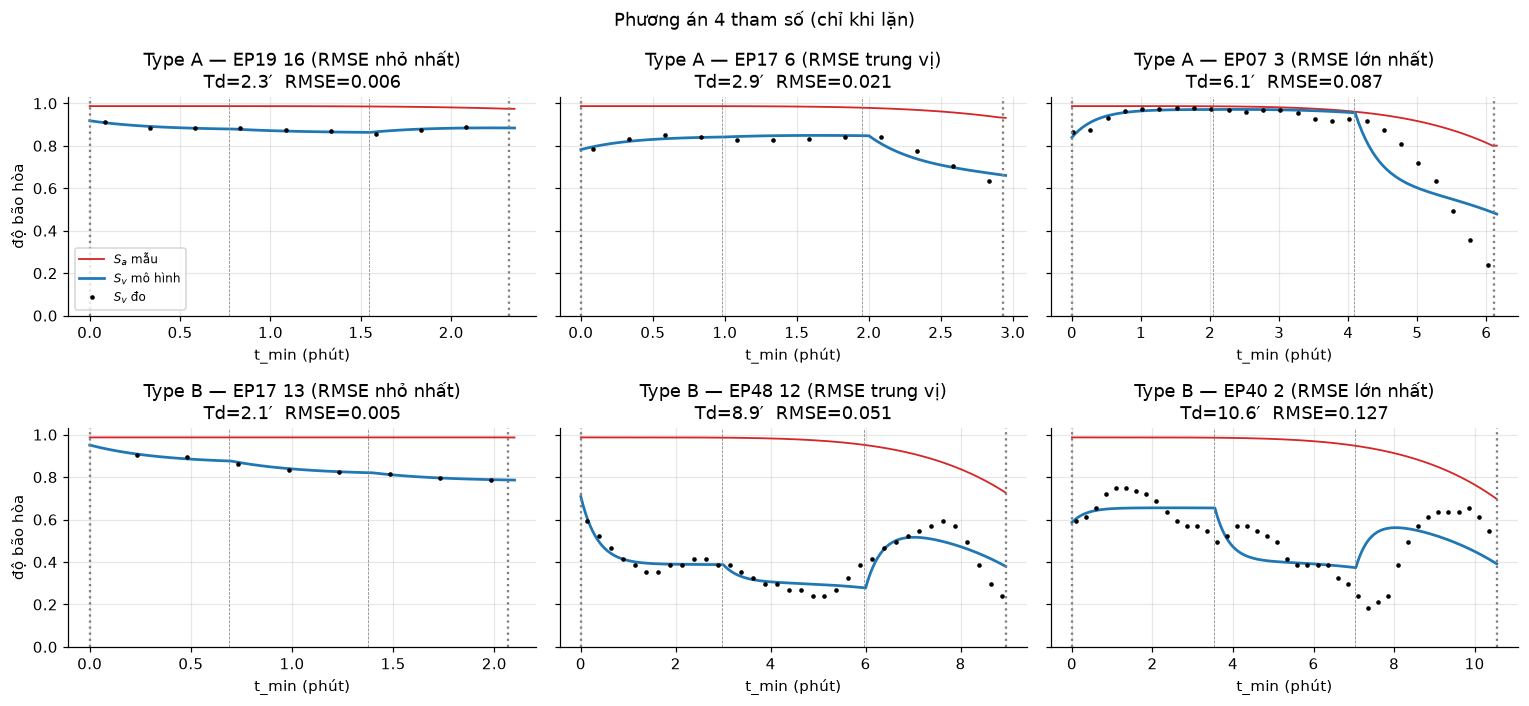

In [15]:
def show_examples(F, preds, curves, mode, title, fname):
    fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharey=True)
    for row_i, tp in enumerate(["A", "B"]):
        sub = F[F.type == tp].sort_values("rmse")
        if len(sub) == 0:
            continue
        picks = [sub.index[0], sub.index[len(sub) // 2], sub.index[-1]]
        for ax, did, lab in zip(axes[row_i], picks, ["RMSE nhỏ nhất", "RMSE trung vị", "RMSE lớn nhất"]):
            s, cv, r = preds[did], curves[did], D.loc[did]
            ax.plot(cv["tg"], cv["Sa"], color="tab:red", lw=1.2, label="$S_a$ mẫu")
            ax.plot(cv["tg"], cv["Sv"], color="tab:blue", lw=1.8, label="$S_v$ mô hình")
            ax.plot(s.tmin, s.S, "k.", ms=4, label="$S_v$ đo")
            for xx in (0, r.Td): ax.axvline(xx, color="gray", ls=":")
            if mode == "dive":
                for xx in (r.Td/3, 2*r.Td/3): ax.axvline(xx, color="gray", ls="--", lw=.5)
            ax.set(title=f"Type {tp} — {did} ({lab})\nTd={r.Td:.1f}′  RMSE={F.at[did,'rmse']:.3f}", ylim=(0, 1.03))
            ax.set_xlabel("t_min (phút)")
        axes[row_i][0].set_ylabel("độ bão hòa")
    axes[0][0].legend(loc="lower left", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(RES_DIR / fname, dpi=150); plt.show()

show_examples(F4, preds4, curves4, "dive", "Phương án 4 tham số (chỉ khi lặn)", "fig_fit_examples_4params.png")

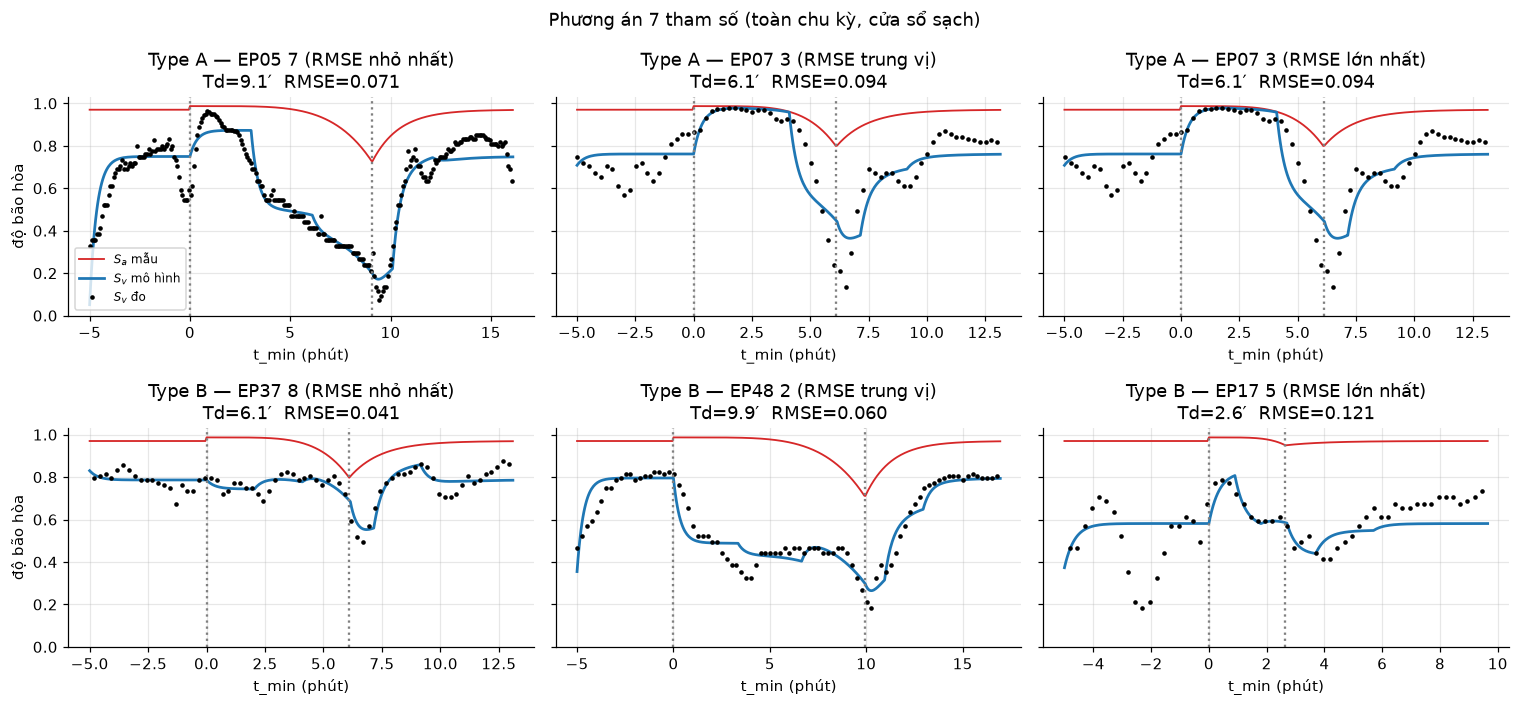

In [16]:
show_examples(F7, preds7, curves7, "window", "Phương án 7 tham số (toàn chu kỳ, cửa sổ sạch)", "fig_fit_examples_7params.png")

### 5.1 So sánh tham số giữa Type A và Type B (phương án 4 tham số)
Kiểm định Mann–Whitney (hai phía), kèm cỡ hiệu ứng $r=1-2U/(n_An_B)$ và quy đổi $g\to$ hiệu số a-v (mL O₂/dL) $=g\times 18\times1{,}34$.
Lưu ý: các cú lặn của cùng một con chim không độc lập (10 cá thể tĩnh mạch) nên p-value mang tính **mô tả**, không phải kết luận suy diễn chặt.

In [17]:
rows = []
for p in ["S_init", "g1", "g2", "g3", "rmse"]:
    a_ = F4.loc[F4.type == "A", p]; b_ = F4.loc[F4.type == "B", p]
    U, pv = stats.mannwhitneyu(a_, b_, alternative="two-sided")
    rows.append(dict(param=p, median_A=a_.median(), median_B=b_.median(), IQR_A=stats.iqr(a_), IQR_B=stats.iqr(b_),
                     U=U, p=pv, effect_r=1 - 2 * U / (len(a_) * len(b_)),
                     avA_mLdL=a_.median() * AV_FACTOR if p.startswith("g") else np.nan,
                     avB_mLdL=b_.median() * AV_FACTOR if p.startswith("g") else np.nan))
CMP = pd.DataFrame(rows).set_index("param"); CMP.to_csv(RES_DIR / "compare_A_vs_B.csv")
print(CMP.round(3).to_string())
print(f"\nSố cú lặn: A={int((F4.type=='A').sum())}, B={int((F4.type=='B').sum())},  số cá thể: A={F4[F4.type=='A'].bird.nunique()}, B={F4[F4.type=='B'].bird.nunique()}")

        median_A  median_B  IQR_A  IQR_B      U      p  effect_r  avA_mLdL  avB_mLdL
param                                                                               
S_init     0.804     0.887  0.192  0.216  587.0  0.007     0.355       NaN       NaN
g1         0.090     0.332  0.120  0.397  147.0  0.000     0.838     2.168     7.998
g2         0.087     0.497  0.117  0.361   39.0  0.000     0.957     2.093    11.987
g3         0.116     0.385  0.261  0.441  387.0  0.000     0.575     2.808     9.295
rmse       0.020     0.051  0.025  0.036  345.0  0.000     0.621       NaN       NaN

Số cú lặn: A=28, B=65,  số cá thể: A=7, B=8


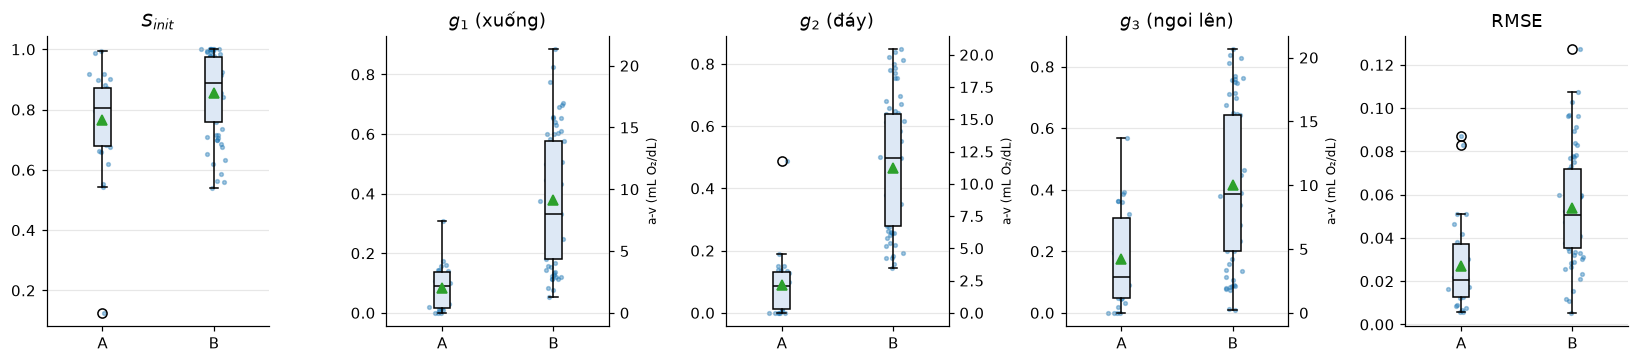

In [18]:
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a_, p, ttl in zip(ax, ["S_init", "g1", "g2", "g3", "rmse"],
                      ["$S_{init}$", "$g_1$ (xuống)", "$g_2$ (đáy)", "$g_3$ (ngoi lên)", "RMSE"]):
    dat = [F4.loc[F4.type == t, p] for t in ("A", "B")]
    bp = a_.boxplot if False else None
    a_.boxplot(dat, tick_labels=["A", "B"], showmeans=True, patch_artist=True,
               boxprops=dict(facecolor="#dde8f5"), medianprops=dict(color="k"))
    for i, d_ in enumerate(dat):
        a_.scatter(np.random.default_rng(0).normal(i + 1, .05, len(d_)), d_, s=6, alpha=.4, color="tab:blue")
    a_.set_title(ttl); a_.grid(axis="x", visible=False)
    if p.startswith("g"):
        sec = a_.secondary_yaxis("right", functions=(lambda v: v * AV_FACTOR, lambda v: v / AV_FACTOR)); sec.set_ylabel("a-v (mL O₂/dL)", fontsize=8)
plt.tight_layout(); plt.savefig(RES_DIR / "fig_params_A_vs_B.png", dpi=150); plt.show()

      S_init  g_rest     g1     g2     g3    gp1    gp2
type                                                   
A      0.380   0.214  0.061  0.248  0.484  0.546  0.221
B      0.594   0.247  0.498  0.520  0.402  0.496  0.283

Số điểm đo trung vị trong mỗi pha:
      n_obs  n_g_rest  n_g1  n_g2  n_g3  n_gp1  n_gp2
type                                                 
A     163.0      72.0  22.5  22.5  22.0    8.0   16.0
B      86.0      36.0  13.0  13.0  12.0    4.0    8.0


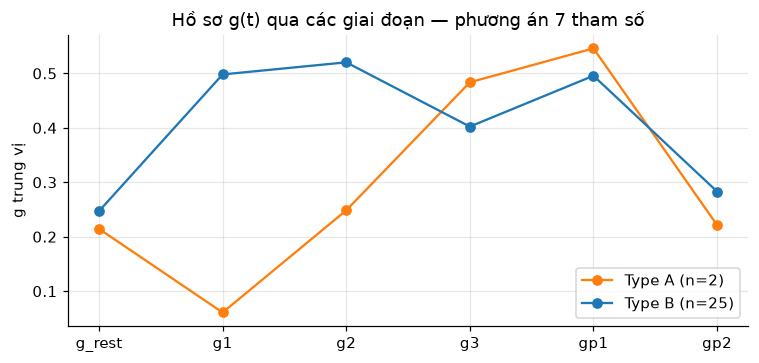

In [19]:
# tham số toàn chu kỳ (Type B đủ mẫu; Type A rất ít cửa sổ sạch)
cols7 = ["S_init", "g_rest", "g1", "g2", "g3", "gp1", "gp2"]
print(F7.groupby("type")[cols7].median().round(3).to_string())
print("\nSố điểm đo trung vị trong mỗi pha:")
print(F7.groupby("type")[[c for c in F7.columns if c.startswith("n_")]].median().to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
for tp, col in (("A", "tab:orange"), ("B", "tab:blue")):
    if (F7.type == tp).sum() == 0: continue
    ax.plot(cols7[1:], F7.loc[F7.type == tp, cols7[1:]].median(), "o-", color=col, label=f"Type {tp} (n={int((F7.type==tp).sum())})")
ax.set(ylabel="g trung vị", title="Hồ sơ g(t) qua các giai đoạn — phương án 7 tham số"); ax.legend()
plt.tight_layout(); plt.savefig(RES_DIR / "fig_g_profile_7params.png", dpi=150); plt.show()

## 6. Kiểm định mô hình

### 6.1 Ngoài mẫu: leave-one-bird-out với $g_1,g_2,g_3$ chung theo nhóm
Mô hình 4 tham số cho từng cú lặn có thể khớp "quá tốt" (4 tham số / vài chục điểm). Để biết cấu trúc 3 pha có *dự báo được* hay không,
ta ước lượng $(g_1,g_2,g_3)$ **chung cho cả nhóm** (mỗi cú lặn vẫn có $S_{init}$ riêng), bỏ lần lượt từng cá thể, rồi dự báo cú lặn của cá thể bị bỏ với $S_{init}$ lấy từ 2 mẫu đo đầu tiên.
Đường chuẩn so sánh: "giữ nguyên $S_v$ = giá trị đầu" (không có động lực học).

In [20]:
def pooled_fit(rows_df):
    blocks, ys, bs, owners = [], [], [], []
    ids = list(rows_df.dive_id)
    for i, did in enumerate(ids):
        r = D.loc[did]; s = get_series(r, "dive"); s = s[(s.tmin >= 0) & (s.tmin <= r.Td)]
        X, b, *_ = build_linear_system(r.Td, s.tmin.to_numpy(), PARAMS_4, "dive")
        Z = np.zeros((len(s), len(ids) + 3)); Z[:, i] = X[:, 0]; Z[:, len(ids):] = X[:, 1:]
        blocks.append(Z); ys.append(s.S.to_numpy() - b)
    A = np.vstack(blocks); y = np.concatenate(ys)
    lb = np.zeros(A.shape[1]); ub = np.r_[np.ones(len(ids)), np.full(3, G_MAX)]
    sol = lsq_linear(A, y, bounds=(lb, ub), method="bvls")
    return dict(zip(["g1", "g2", "g3"], sol.x[-3:]))

def predict_with_g(did, gdict):
    r = D.loc[did]; s = get_series(r, "dive"); s = s[(s.tmin >= 0) & (s.tmin <= r.Td)]
    X, b, *_ = build_linear_system(r.Td, s.tmin.to_numpy(), PARAMS_4, "dive")
    S0 = np.clip(s.S.iloc[:2].mean(), 0, 1)
    pred = X @ np.r_[S0, [gdict["g1"], gdict["g2"], gdict["g3"]]] + b
    naive = np.full(len(s), S0)
    return s.S.to_numpy(), pred, naive

rows_cv, pooled_g = [], {}
for tp in ("A", "B"):
    sub = F4[F4.type == tp]
    pooled_g[tp] = pooled_fit(sub.reset_index())
    for bird in sub.bird.unique():
        g_tr = pooled_fit(sub[sub.bird != bird].reset_index())
        for did in sub.index[sub.bird == bird]:
            y, p, nv = predict_with_g(did, g_tr)
            rows_cv.append(dict(dive_id=did, type=tp, bird=bird, rmse_lobo=np.sqrt(np.mean((y - p)**2)),
                                rmse_naive=np.sqrt(np.mean((y - nv)**2)), rmse_perdive=F4.at[did, "rmse"]))
CV = pd.DataFrame(rows_cv)
summ = CV.groupby("type")[["rmse_perdive", "rmse_lobo", "rmse_naive"]].median().round(3)
summ["lobo_beats_naive_%"] = CV.groupby("type").apply(lambda d_: 100 * (d_.rmse_lobo < d_.rmse_naive).mean(), include_groups=False).round(0)
print("g chung theo nhóm (toàn bộ dữ liệu):", {k: {p: round(v, 3) for p, v in d_.items()} for k, d_ in pooled_g.items()})
print(); print(summ.to_string())
CV.to_csv(RES_DIR / "validation_lobo.csv", index=False)

g chung theo nhóm (toàn bộ dữ liệu): {'A': {'g1': np.float64(0.063), 'g2': np.float64(0.157), 'g3': np.float64(0.258)}, 'B': {'g1': np.float64(0.386), 'g2': np.float64(0.499), 'g3': np.float64(0.474)}}

      rmse_perdive  rmse_lobo  rmse_naive  lobo_beats_naive_%
type                                                         
A            0.020      0.131       0.076                36.0
B            0.051      0.258       0.224                55.0


### 6.2 Độ nhạy theo $\tau$
$\tau=V_v/Q$ không nằm trong $\Theta$ mà được cố định. Quét $\tau$ và xem tổng sai số — nếu đường cong phẳng thì kết luận không phụ thuộc mạnh vào lựa chọn $\tau$.

     rmse_median            g1            g2            g3       
type           A      B      A      B      A      B      A      B
tau                                                              
0.10       0.025  0.063  0.102  0.301  0.084  0.483  0.098  0.376
0.15       0.023  0.063  0.103  0.303  0.085  0.486  0.101  0.375
0.25       0.022  0.055  0.097  0.313  0.088  0.493  0.107  0.377
0.35       0.020  0.051  0.090  0.332  0.087  0.497  0.116  0.385
0.50       0.019  0.050  0.074  0.347  0.085  0.494  0.131  0.391
0.75       0.017  0.047  0.037  0.378  0.074  0.483  0.151  0.386
1.00       0.018  0.045  0.000  0.409  0.079  0.463  0.169  0.402
1.50       0.020  0.046  0.000  0.461  0.079  0.424  0.191  0.444


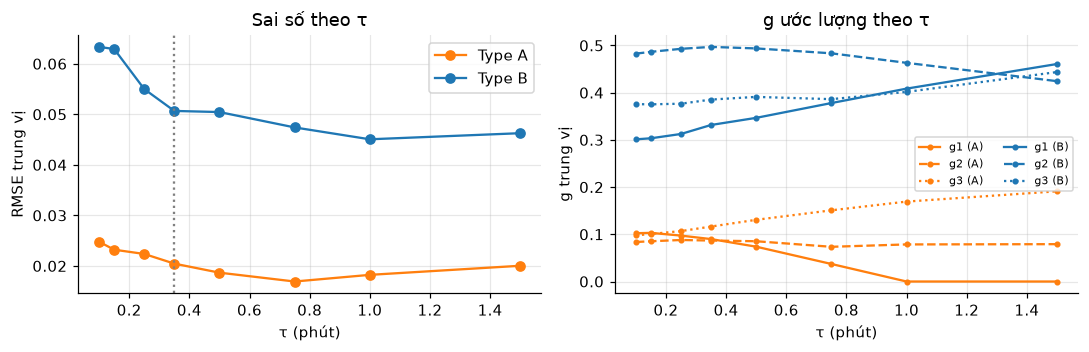

In [21]:
taus = [0.10, 0.15, 0.25, 0.35, 0.50, 0.75, 1.0, 1.5]
sens = []
for tau in taus:
    for tp in ("A", "B"):
        rm, g1m, g2m, g3m = [], [], [], []
        for r in ven[ven.type == tp].itertuples():
            o, *_ = fit_dive(D.loc[r.dive_id], "dive", tau=tau)
            rm.append(o["rmse"]); g1m.append(o["g1"]); g2m.append(o["g2"]); g3m.append(o["g3"])
        sens.append(dict(tau=tau, type=tp, rmse_median=np.median(rm), g1=np.median(g1m), g2=np.median(g2m), g3=np.median(g3m)))
SENS = pd.DataFrame(sens); SENS.to_csv(RES_DIR / "sensitivity_tau.csv", index=False)
print(SENS.pivot(index="tau", columns="type", values=["rmse_median", "g1", "g2", "g3"]).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for tp, c in (("A", "tab:orange"), ("B", "tab:blue")):
    d_ = SENS[SENS.type == tp]
    ax[0].plot(d_.tau, d_.rmse_median, "o-", color=c, label=f"Type {tp}")
    for gname, ls in (("g1", "-"), ("g2", "--"), ("g3", ":")):
        ax[1].plot(d_.tau, d_[gname], ls, color=c, marker=".", label=f"{gname} ({tp})")
ax[0].axvline(TAU, color="gray", ls=":"); ax[0].set(xlabel="τ (phút)", ylabel="RMSE trung vị", title="Sai số theo τ"); ax[0].legend()
ax[1].set(xlabel="τ (phút)", ylabel="g trung vị", title="g ước lượng theo τ"); ax[1].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.savefig(RES_DIR / "fig_sensitivity_tau.png", dpi=150); plt.show()

### 6.3 Nghịch đảo trực tiếp $g(t)$ (không giả định hằng từng đoạn)
Từ (9): $g_j=S_a(t_j)-\dfrac{S_{v,j+1}-aS_{v,j}}{1-a}$. Công thức khuếch đại nhiễu (hệ số $1/(1-a)\approx 7{,}5$ với $\tau=0{,}35$), nên $S_v$ đo được nội suy lên lưới 0,05 phút
và làm trơn Savitzky–Golay trước khi nghịch đảo. Dùng để *kiểm tra* xem giả định 3 đoạn hằng có hợp lý không.

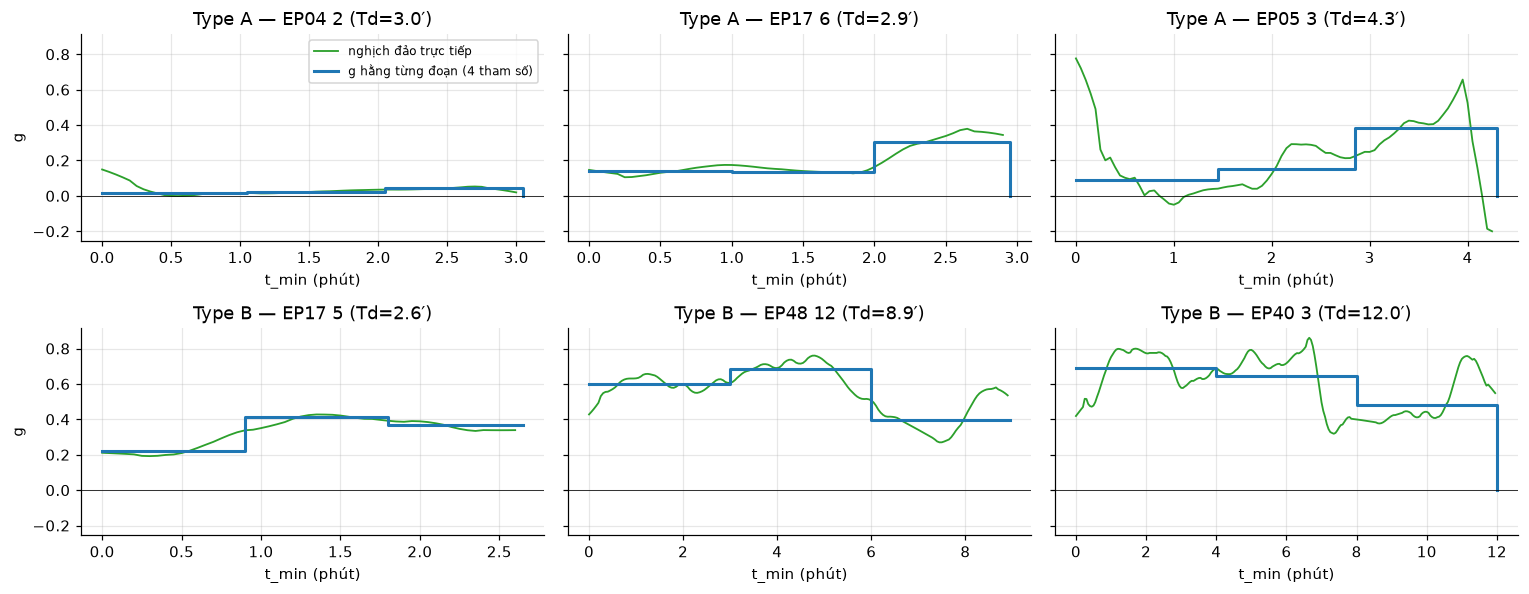

In [22]:
def g_inverse(did, tau=TAU, win_min=0.6):
    r = D.loc[did]; s = get_series(r, "dive"); s = s[(s.tmin >= 0) & (s.tmin <= r.Td)]
    tg = make_grid(r.Td, "dive")
    Sv = np.interp(tg, s.tmin, s.S)
    w = max(5, int(win_min / DT) // 2 * 2 + 1)
    Sv_s = savgol_filter(Sv, w, 2)
    a = np.exp(-DT / tau)
    g = sa_curve(tg[:-1], r.Td, **SA_PARAMS) - (Sv_s[1:] - a * Sv_s[:-1]) / (1 - a)
    return tg[:-1], np.clip(g, -0.2, 1.0)

fig, axes = plt.subplots(2, 3, figsize=(14, 5.5), sharey=True)
for row_i, tp in enumerate(["A", "B"]):
    sub = F4[F4.type == tp].sort_values("rmse")
    for ax, did in zip(axes[row_i], [sub.index[1], sub.index[len(sub)//2], sub.index[-2]]):
        tgi, gi = g_inverse(did); r = D.loc[did]
        ax.plot(tgi, gi, color="tab:green", lw=1.2, label="nghịch đảo trực tiếp")
        ax.step(make_grid(r.Td, "dive"), g_of_t(make_grid(r.Td, "dive"), r.Td, F4.loc[did]), where="post", color="tab:blue", lw=2, label="g hằng từng đoạn (4 tham số)")
        ax.set(title=f"Type {tp} — {did} (Td={r.Td:.1f}′)", xlabel="t_min (phút)"); ax.axhline(0, color="k", lw=.5)
    axes[row_i][0].set_ylabel("g")
axes[0][0].legend(fontsize=8); plt.tight_layout(); plt.savefig(RES_DIR / "fig_g_inverse.png", dpi=150); plt.show()

## 7. Tóm tắt số liệu để đưa vào báo cáo

In [23]:
summary = {
    "Sa_k": round(K_SA, 3), "Sa_tau_a_min": round(TAU_A, 3), "tau_min": TAU,
    "n_dives_4params": {t: int((F4.type == t).sum()) for t in "AB"},
    "n_dives_7params_clean": {t: int((F7.type == t).sum()) for t in "AB"},
    "rmse_median_4params": F4.groupby("type").rmse.median().round(4).to_dict(),
    "rmse_median_7params": F7.groupby("type").rmse.median().round(4).to_dict(),
    "r2_median_4params": F4.groupby("type").r2.median().round(3).to_dict(),
    "g_median_4params": F4.groupby("type")[["g1", "g2", "g3"]].median().round(3).to_dict("index"),
    "av_diff_mLdL_median": (F4.groupby("type")[["g1", "g2", "g3"]].median() * AV_FACTOR).round(2).to_dict("index"),
}
json.dump(summary, open(RES_DIR / "summary.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(summary, indent=1, ensure_ascii=False))

{
 "Sa_k": 4.937,
 "Sa_tau_a_min": 1.341,
 "tau_min": 0.35,
 "n_dives_4params": {
  "A": 28,
  "B": 65
 },
 "n_dives_7params_clean": {
  "A": 2,
  "B": 25
 },
 "rmse_median_4params": {
  "A": 0.0205,
  "B": 0.0507
 },
 "rmse_median_7params": {
  "A": 0.0825,
  "B": 0.0597
 },
 "r2_median_4params": {
  "A": 0.822,
  "B": 0.798
 },
 "g_median_4params": {
  "A": {
   "g1": 0.09,
   "g2": 0.087,
   "g3": 0.116
  },
  "B": {
   "g1": 0.332,
   "g2": 0.497,
   "g3": 0.385
  }
 },
 "av_diff_mLdL_median": {
  "A": {
   "g1": 2.17,
   "g2": 2.09,
   "g3": 2.81
  },
  "B": {
   "g1": 8.0,
   "g2": 11.99,
   "g3": 9.3
  }
 }
}
